<a href="https://colab.research.google.com/github/syeda-bisma05/weather-data-analysis/blob/main/weather_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Historical Weather Data Analysis

This notebook explores 11 years (2006 to 2016) of hourly weather data, including temperature, humidity, wind speed, pressure and visibility. It cleans the data, checks for missing values, duplicates and outliers, and uses graphs to find patterns in the weather.
## Questions

**Single column:**
1. How is temperature distributed, and what is the typical value?
2. How is wind speed distributed, and are there extreme values?
3. How often does each precipitation type (rain or snow) occur?

**Two columns:**

4. What is the relationship between temperature and humidity?
5. How does the average temperature change across months?

##Step 1: Basic Analysis

In [1]:
from google.colab import files
uploaded = files.upload()

Saving weather_data.csv to weather_data.csv


In [ ]:
!pip install pandas numpy matplotlib seaborn plotly

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
df = pd.read_csv('weather_data.csv')

In [4]:
df.shape

(96453, 14)

**Shape (df.shape):** The dataset has 96,453 rows and 14 columns.



In [5]:
df.head()

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
0,4/1/2006,00:00:00.000,Partly Cloudy,rain,9.472222,7.388889,14.1197,251.0,15.8263,1015.13,0.89,4,1,2006
1,4/1/2006,01:00:00.000,Partly Cloudy,rain,9.355556,7.227778,14.2646,259.0,15.8263,1015.63,0.86,4,1,2006
2,4/1/2006,02:00:00.000,Mostly Cloudy,rain,9.377778,9.377778,3.9284,204.0,14.9569,1015.94,0.89,4,1,2006
3,4/1/2006,03:00:00.000,Partly Cloudy,rain,8.288889,5.944444,14.1036,269.0,15.8263,1016.41,0.83,4,1,2006
4,4/1/2006,04:00:00.000,Mostly Cloudy,rain,8.755556,6.977778,11.0446,259.0,15.8263,1016.51,0.83,4,1,2006


**First rows (df.head()):** Each row is one hourly weather reading. The first rows show the date, time, summary, precipitation type, temperature and other measurements.



In [6]:
df.columns

Index(['Formatted Date', 'Time', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)',
       'Humidity', 'Month', 'Day', 'Year'],
      dtype='object')

**Columns (df.columns):** The data has weather columns (temperature, apparent temperature, wind speed, wind bearing, visibility, pressure, humidity), date columns (Formatted Date, Time, Month, Day, Year) and two text columns (Summary, Precip Type).



In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Time                      96453 non-null  object 
 2   Summary                   96453 non-null  object 
 3   Precip Type               95936 non-null  object 
 4   Temperature (C)           96453 non-null  float64
 5   Apparent Temperature (C)  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Pressure (millibars)      96453 non-null  float64
 10  Humidity                  96453 non-null  float64
 11  Month                     96453 non-null  int64  
 12  Day                       96453 non-null  int64  
 13  Year                      96453 non-null  int64  
dtypes: flo

**Data types (df.info()):** There are 7 float, 3 integer and 4 object columns. Only Precip Type has missing values (517 out of 96,453). Formatted Date is stored as text (object), so it needs to be converted to a date type.

In [8]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], format='%m/%d/%Y')
print(df['Formatted Date'].dtype)
print(df['Formatted Date'].min(), df['Formatted Date'].max())

datetime64[ns]
2006-01-01 00:00:00 2016-12-31 00:00:00






**Date conversion:** I converted Formatted Date to datetime using pd.to_datetime so I can sort by date, filter by date range and plot trends over time. The data runs from 2006-01-01 to 2016-12-31 (11 years of hourly data).

**Places:** There is no place or country column, so the data covers a single location. There is also no rainfall column, so I use Precip Type (rain or snow) and humidity instead. Because of this, I will compare by Month and Precip Type instead of countries.



In [9]:

df.describe()

,Formatted Date,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,2011-07-02 09:45:39.386022400,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
min,2006-01-01 00:00:00,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,2008-10-01 00:00:00,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,2011-07-02 00:00:00,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,2014-04-02 00:00:00,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,2016-12-31 00:00:00,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000
std,NaN,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142


**Summary statistics (df.describe()):** The data has 96,453 hourly records from 2006-01-01 to 2016-12-31.

- **Temperature:** The average is about 11.9 C and the middle value (median) is 12.0 C. It ranges from -21.8 C to 39.9 C, which is realistic for this kind of climate.
- **Wind speed:** The average is about 10.8 km/h, and the maximum is 63.9 km/h. This is far above the 75th percentile (14.1 km/h), so it may be a real storm. I will check it in the outlier step.
- **Humidity:** The average is 0.73 and the median is 0.78. Most values are between 0.60 and 0.89. The minimum is 0, which is suspicious because humidity is almost never exactly zero.
- **Pressure:** The median is about 1016 millibars, but the minimum is 0 and the mean (1003) is lower than the median. Zero pressure is not physically possible, so these values look like data errors. I will check them in the outlier step.
- **Visibility:** The average is about 10.3 km and the maximum is 16.1 km. A minimum of 0 km can happen in heavy fog, so I will check it before treating it as an error.


In [10]:
cols = ['Formatted Date', 'Precip Type', 'Temperature (C)',
        'Apparent Temperature (C)', 'Wind Speed (km/h)',
        'Visibility (km)', 'Pressure (millibars)', 'Humidity',
        'Month', 'Year',]

df = df[cols].sort_values('Formatted Date').reset_index(drop=True)
df.head(3)

,Formatted Date,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Visibility (km),Pressure (millibars),Humidity,Month,Year
0,2006-01-01,rain,5.472222,1.377778,22.7171,14.7959,1009.51,0.87,1,2006
1,2006-01-01,rain,5.422222,1.666667,19.5615,15.6492,1009.64,0.86,1,2006
2,2006-01-01,rain,4.933333,0.555556,23.9407,15.7297,1009.43,0.86,1,2006


**Selecting columns:** I kept only the columns needed for my questions: date, precipitation type, temperature, apparent temperature, wind speed, visibility, pressure, humidity, month and year. I dropped Time, Summary, Wind Bearing and Day because my questions do not use them. The data is now sorted by date.
##Step 2: Missing values

In [11]:
missing = df.isnull().sum()
missing

,0
Formatted Date,0
Precip Type,517
Temperature (C),0
Apparent Temperature (C),0
Wind Speed (km/h),0
Visibility (km),0
Pressure (millibars),0
Humidity,0
Month,0
Year,0


Only the Precip Type column has missing values (517 out of 96,453 rows, about 0.5%). All other 13 columns are complete.

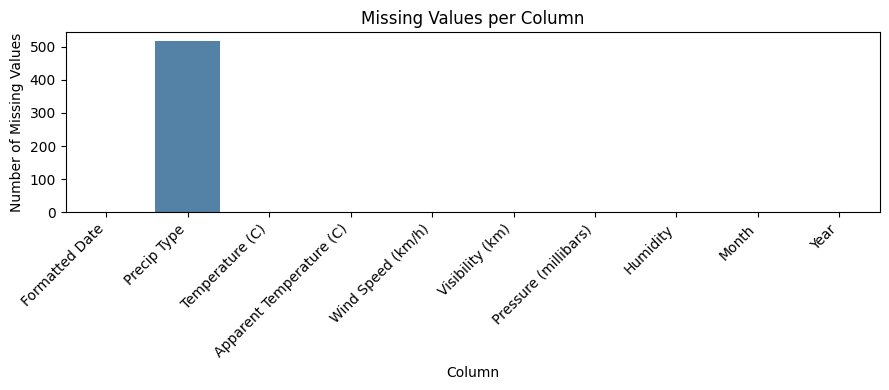

In [12]:
plt.figure(figsize=(9, 4))
sns.barplot(x=missing.index, y=missing.values, color='steelblue')
plt.title('Missing Values per Column')
plt.xlabel('Column')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The bar chart shows that only the Precip Type column has missing values (about 517), while all other columns have none. This means the missing data problem is small and limited to one column.

In [13]:
df['Precip Type'] = df['Precip Type'].ffill().bfill()
df.isnull().sum().sum()


np.int64(0)



**Decision (Precip Type):** I filled the missing values with the previous value (forward fill).

**Why I chose this method:**
- I did not drop the rows, because that would remove valid temperature, humidity and wind readings from those hours.
- I did not use the median, because Precip Type is a text column (rain or snow), not a number.
- The data is hourly and sorted by date, so the precipitation type usually stays the same from one hour to the next. The previous hour is therefore a reasonable guess for a missing hour.
- If the very first row were missing, I used the next value (backward fill), so no gaps are left.

**Decision (other columns):** No action is needed for the other columns because they have no missing values.

**Result:** After filling, the total number of missing values is 0.
##Step 3: Duplicates

In [14]:
raw = pd.read_csv('weather_data.csv')
print('Duplicate rows:', raw.duplicated().sum())
print('Repeated date + time:', raw.duplicated(subset=['Formatted Date', 'Time']).sum())

Duplicate rows: 24
Repeated date + time: 35


In [15]:
same_time = raw[raw.duplicated(subset=['Formatted Date', 'Time'], keep=False)]
same_time.sort_values(['Formatted Date', 'Time']).head(12)

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
34033,10/25/2009,02:00:00.000,Foggy,rain,12.172222,12.172222,6.2307,308.0,2.7853,1020.20,0.93,10,25,2009
34034,10/25/2009,02:00:00.000,Mostly Cloudy,rain,11.111111,11.111111,6.4400,330.0,8.0500,1016.60,0.93,10,25,2009
86614,10/25/2015,02:00:00.000,Foggy,rain,2.883333,2.883333,3.2039,142.0,1.2880,1024.71,0.96,10,25,2015
86615,10/25/2015,02:00:00.000,Foggy,rain,1.783333,1.783333,3.2039,131.0,0.7567,1024.28,1.00,10,25,2015
25297,10/26/2008,02:00:00.000,Mostly Cloudy,rain,8.150000,8.150000,3.8801,157.0,6.1663,1025.71,0.84,10,26,2008
25298,10/26/2008,02:00:00.000,Partly Cloudy,rain,7.800000,6.788889,6.6010,272.0,6.0697,1031.90,0.86,10,26,2008
77878,10/26/2014,02:00:00.000,Overcast,rain,7.500000,7.500000,2.8658,162.0,4.5402,1027.59,0.96,10,26,2014
77879,10/26/2014,02:00:00.000,Overcast,rain,7.177778,7.177778,3.0751,240.0,4.5241,1027.40,0.96,10,26,2014
69145,10/27/2013,02:00:00.000,Foggy,rain,10.650000,10.650000,2.9302,218.0,1.4490,1020.87,0.96,10,27,2013
69146,10/27/2013,02:00:00.000,Foggy,rain,10.488889,10.488889,6.1502,150.0,0.3542,1020.60,0.93,10,27,2013




The data has no place column and has one row per hour, so I checked duplicates using Formatted Date together with Time.

- **Fully duplicated rows:** 24
- **Repeated date and time:** 35 (24 are the exact duplicates above, and 11 have the same date and time but different values)

**Checking the 11 rows:** All of them fall at 02:00 in the last week of October, exactly one in each of the 11 years. This is when the clocks go back (daylight saving time), so that hour happens twice and the two readings have different values. These are real measurements, not errors.

**Decision:** I removed the 24 exact duplicates because they add no new information. I kept the 11 daylight saving rows because they are real data. After cleaning, the dataset has 96,429 rows.

In [16]:
raw = raw.drop_duplicates()

df = raw.copy()
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], format='%m/%d/%Y')
cols = ['Formatted Date', 'Precip Type', 'Temperature (C)',
        'Apparent Temperature (C)', 'Wind Speed (km/h)',
        'Visibility (km)', 'Pressure (millibars)', 'Humidity',
        'Month', 'Year']
df = df[cols].sort_values('Formatted Date').reset_index(drop=True)
df['Precip Type'] = df['Precip Type'].ffill().bfill()

print('Rows now:', len(df))

Rows now: 96429


After removing the 24 exact duplicates, the dataset has 96,429 rows. No fully duplicated rows remain, and the only repeated date and time values are the 11 daylight saving hours, which are real readings.
##Step 4: Outliers

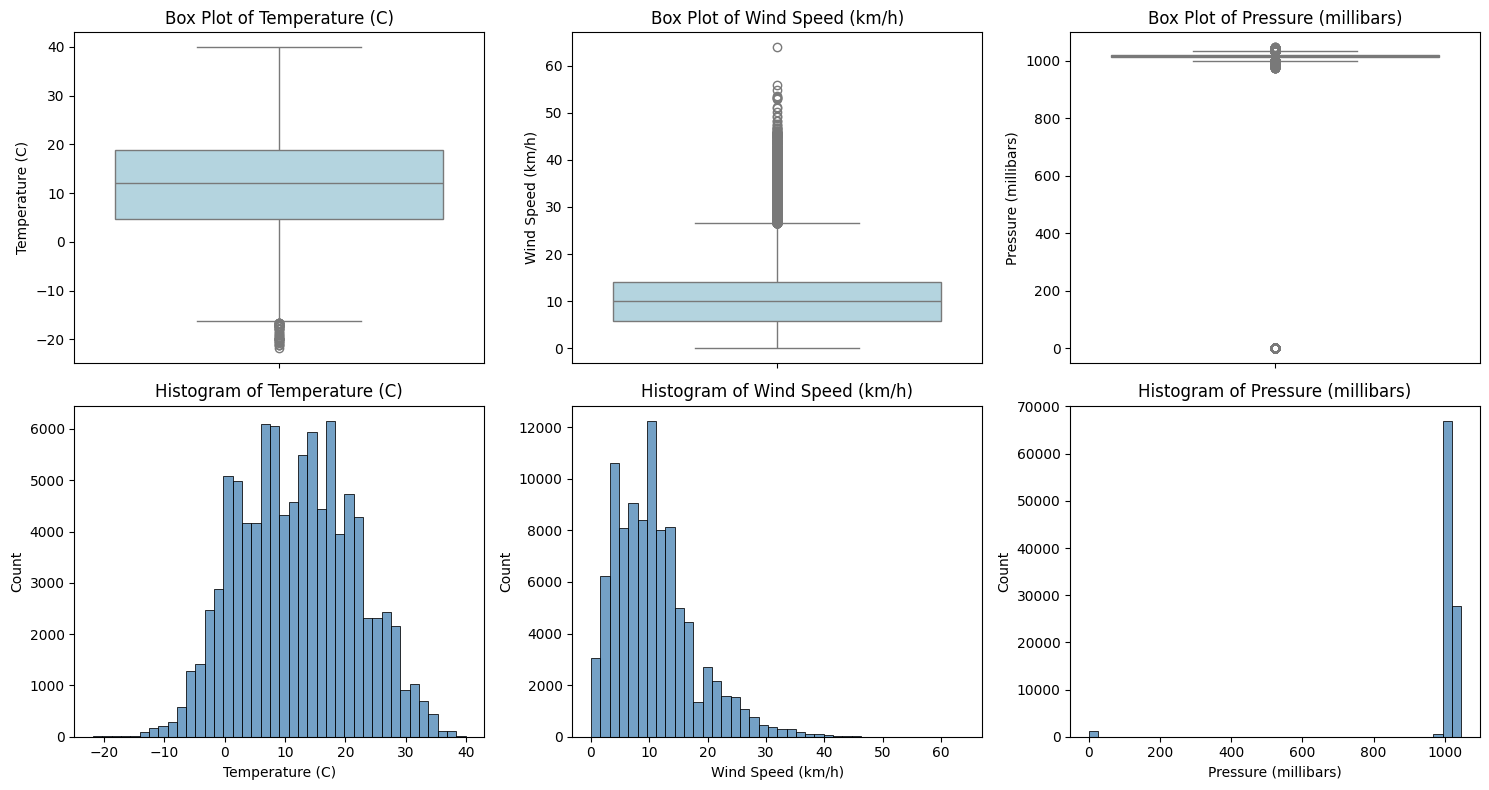

In [17]:
cols = ['Temperature (C)', 'Wind Speed (km/h)', 'Pressure (millibars)']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(cols):
    sns.boxplot(y=df[c], ax=axes[0, i], color='lightblue')
    axes[0, i].set_title(f'Box Plot of {c}')
    axes[0, i].set_ylabel(c)
    sns.histplot(df[c], bins=40, ax=axes[1, i], color='steelblue')
    axes[1, i].set_title(f'Histogram of {c}')
    axes[1, i].set_xlabel(c)
    axes[1, i].set_ylabel('Count')
plt.tight_layout()
plt.show()

**Box plots and histograms (Temperature, Wind Speed, Pressure):**

- **Temperature:** The histogram is roughly bell-shaped and centered around 10 to 15 C. The box plot shows a few low outliers below about -16 C, but none on the high side. These cold readings look like real winter weather.
- **Wind speed:** The histogram is right-skewed. Most readings are between 0 and 20 km/h, with a long tail up to about 64 km/h. The box plot shows many high outliers, which are likely real strong wind or storm events.
- **Pressure:** The box plot and histogram are squeezed into a very narrow range near 1000 to 1040 millibars, because of a small group of values at 0. A pressure of 0 is not physically possible, so these look like data errors. There are also a few real outliers just outside the normal range.

In [18]:
rows = []
for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    rows.append({'Column': c, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                 'Lower Limit': low, 'Upper Limit': high,
                 'Outliers': n, 'Outliers (%)': n / len(df) * 100})

iqr_table = pd.DataFrame(rows).set_index('Column').round(2)
iqr_table

,Q1,Q3,IQR,Lower Limit,Upper Limit,Outliers,Outliers (%)
Column,,,,,,,
Temperature (C),4.68,18.84,14.16,-16.55,40.07,44,0.05
Wind Speed (km/h),5.83,14.14,8.31,-6.63,26.60,3020,3.13
Pressure (millibars),1011.90,1021.09,9.19,998.11,1034.88,4400,4.56


**IQR rule results (Temperature, Wind Speed, Pressure):**

- **Temperature:** The IQR is 14.16 and the limits are -16.55 C and 40.07 C. Only 44 values (0.05%) are outliers. The highest reading (39.9 C) is below the upper limit, so all of them are very cold readings. These are real winter cold spells.
- **Wind speed:** The IQR is 8.31 and the upper limit is 26.60 km/h. There are 3,020 outliers (3.13%), all on the high side, because the lower limit is below zero. Wind speed is right-skewed, so strong wind hours are flagged. These look like real windy or stormy hours.
- **Pressure:** The IQR is only 9.19, so the limits are narrow (998.11 to 1034.88 millibars). There are 4,400 outliers (4.56%). Most of them are real low-pressure or high-pressure weather, but the list also contains the impossible zero values, which I check in the next step.

In [19]:
print('Pressure = 0 rows:', (df['Pressure (millibars)'] == 0).sum())
print('Max wind speed row:')
df.loc[df['Wind Speed (km/h)'].idxmax()]

Pressure = 0 rows: 1288
Max wind speed row:


,9432
Formatted Date,2007-01-29 00:00:00
Precip Type,rain
Temperature (C),8.944444
Apparent Temperature (C),3.483333
Wind Speed (km/h),63.8526
Visibility (km),11.4471
Pressure (millibars),1009.05
Humidity,0.49
Month,1
Year,2007


**Checking suspicious values:**

- **Pressure = 0:** There are 1,288 rows (about 1.3% of the data) with a pressure of exactly 0 millibars. This is physically impossible, since normal pressure is around 980 to 1045 millibars, so these are data errors.
- **Maximum wind speed:** The highest reading is 63.85 km/h, recorded on 29 January 2007. The temperature (8.9 C), pressure (1009 millibars) and humidity (0.49) for that hour are all normal, so this is a real strong wind event and not a mistake.

In [20]:
df['Pressure (millibars)'] = df['Pressure (millibars)'].replace(0, np.nan)
df['Pressure (millibars)'] = df['Pressure (millibars)'].ffill().bfill()
print('Pressure = 0 rows now:', (df['Pressure (millibars)'] == 0).sum())
print('Missing now:', df['Pressure (millibars)'].isnull().sum())
df['Pressure (millibars)'].describe()

Pressure = 0 rows now: 0
Missing now: 0


,Pressure (millibars)
count,96429.000000
mean,1016.818253
std,7.780788
min,973.780000
25%,1012.120000
50%,1016.560000
75%,1021.170000
max,1046.380000


**Result after fixing pressure:** There are no zero or missing pressure values now. Pressure ranges from 973.78 to 1046.38 millibars, which is normal. The mean (1016.8) is now very close to the median (1016.6), so the zeros no longer pull the average down.

**Outliers: real or mistake?**

- **Temperature (44 outliers):** Very cold winter days. Real, kept.
- **Wind speed (3,020 outliers):** Strong wind or storm hours. The highest value (63.85 km/h) happened on a day with normal temperature and pressure. Real, kept.
- **Pressure = 0 (1,288 rows):** Zero pressure is impossible, so this is a data error. Mistake, fixed by using the previous hour's value.
- **Other pressure outliers:** Normal high and low pressure weather. Real, kept.


In [23]:
print('Humidity = 0 rows:', (df['Humidity'] == 0).sum())
print('Visibility = 0 rows:', (df['Visibility (km)'] == 0).sum())

Humidity = 0 rows: 22
Visibility = 0 rows: 450


There are 22 rows with Humidity equal to 0 and 450 rows with Visibility equal to 0. Humidity of exactly 0 is almost impossible, and zero visibility in clear or cloudy weather makes no sense, so I check these rows further before deciding what to do.

In [24]:
print(raw[raw['Visibility (km)'] == 0]['Summary'].value_counts().head())
print()
print(raw[raw['Humidity'] == 0][['Summary', 'Pressure (millibars)', 'Wind Speed (km/h)']].head())

Summary
Clear            271
Foggy             86
Mostly Cloudy     36
Partly Cloudy     27
Breezy             9
Name: count, dtype: int64

             Summary  Pressure (millibars)  Wind Speed (km/h)
19958  Partly Cloudy               1043.04             4.4275
28101          Clear               1015.10             3.2200
28103          Clear               1015.90             6.4400
28110          Clear               1016.80            22.5400
29627          Foggy               1000.10            20.9300


**Checking Humidity and Visibility zeros:**

- **Humidity = 0 (22 rows):** In these rows, pressure and wind speed are normal, but humidity is exactly 0, which is almost impossible in clear or cloudy weather. These are data errors. Mistake, fixed with the previous hourly value.
- **Visibility = 0 (450 rows, about 0.5%):** Only 86 of these rows are Foggy. Most are Clear (271), Mostly Cloudy (36) or Partly Cloudy (27), where zero visibility makes no sense. These are data errors. Mistake, fixed with the previous hourly value.

In [25]:
df['Humidity'] = df['Humidity'].replace(0, np.nan)
df['Humidity'] = df['Humidity'].ffill().bfill()

df['Visibility (km)'] = df['Visibility (km)'].replace(0, np.nan)
df['Visibility (km)'] = df['Visibility (km)'].ffill().bfill()

print('Humidity = 0 rows now:', (df['Humidity'] == 0).sum())
print('Visibility = 0 rows now:', (df['Visibility (km)'] == 0).sum())

Humidity = 0 rows now: 0
Visibility = 0 rows now: 0


After the fix, there are no zero values left in Humidity or Visibility (both counts are 0). The zeros were replaced with the previous hourly value, so these two columns no longer contain impossible values.

##Step 5: Univariate analysis

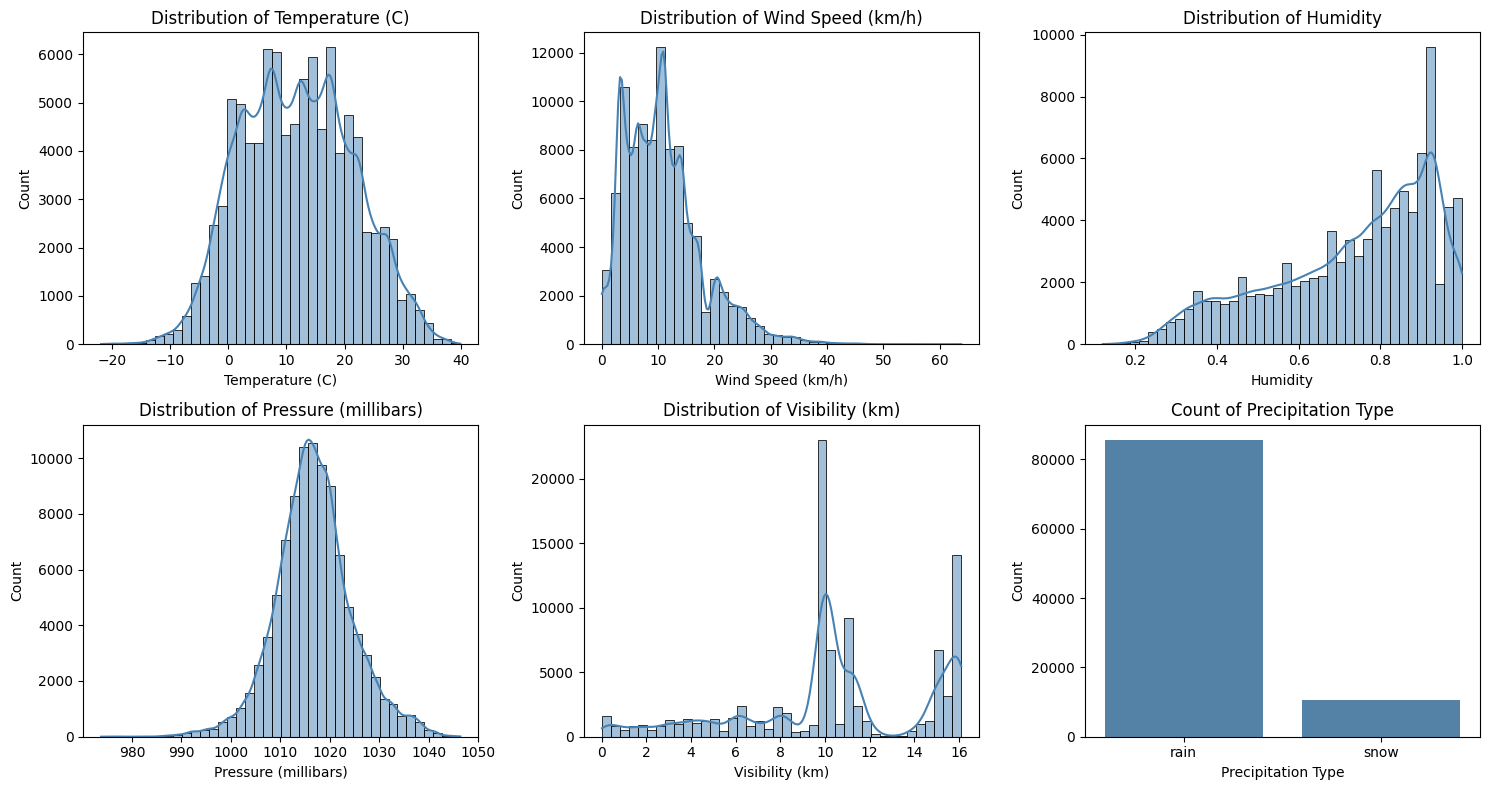

In [26]:
num_cols = ['Temperature (C)', 'Wind Speed (km/h)', 'Humidity',
            'Pressure (millibars)', 'Visibility (km)']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of {c}')
    axes[i].set_xlabel(c)
    axes[i].set_ylabel('Count')

sns.countplot(x='Precip Type', data=df, ax=axes[5], color='steelblue')
axes[5].set_title('Count of Precipitation Type')
axes[5].set_xlabel('Precipitation Type')
axes[5].set_ylabel('Count')

plt.tight_layout()
plt.show()

**Observation (distribution of each column):**

- **Temperature:** The shape is roughly bell-shaped with a few small peaks. Most values are between 0 and 25 C, and the typical value is about 12 C. The spread is wide because the data covers all seasons.
- **Wind speed:** The distribution is right-skewed. Most hours have 5 to 15 km/h wind, and only a few hours have strong wind above 30 km/h.
- **Humidity:** The distribution is left-skewed. Most values are high, between 0.6 and 1.0, with the highest peak near 0.9. This means the weather is humid most of the time. The zero values are gone after cleaning.
- **Pressure:** The distribution is a clean bell shape centered at about 1016 millibars, and the spread is small. Pressure stays stable.
- **Visibility:** The distribution is uneven. There are two big peaks, at about 10 km and about 16 km, and a small number of low visibility hours between 0 and 8 km (likely fog or rain).
- **Precipitation type:** Rain is far more common than snow, with about 85,000 rain hours compared to about 10,000 snow hours.

In [27]:
summary = df[num_cols].agg(['mean', 'median', 'std', 'min', 'max']).T.round(2)
summary

,mean,median,std,min,max
Temperature (C),11.93,12.00,9.55,-21.82,39.91
Wind Speed (km/h),10.81,9.97,6.91,0.00,63.85
Humidity,0.74,0.78,0.20,0.12,1.00
Pressure (millibars),1016.82,1016.56,7.78,973.78,1046.38
Visibility (km),10.39,10.05,4.15,0.02,16.10


**Typical value and spread (summary table):**

- **Temperature:** The typical value (median) is 12.0 C and the mean is 11.93 C, so they are almost the same. The standard deviation is 9.55 C and the range is -21.82 to 39.91 C, so the spread is wide because the data covers all seasons.
- **Wind speed:** The median is 9.97 km/h and the mean is 10.81 km/h. The mean is higher than the median because of a few very strong wind hours (maximum 63.85 km/h). The standard deviation is 6.91 km/h.
- **Humidity:** The median is 0.78 and the mean is 0.74. The mean is lower than the median because of some low humidity values, which matches the left-skewed graph. The standard deviation is 0.20 and the range is 0.12 to 1.00.
- **Pressure:** The median (1016.56 millibars) and the mean (1016.82) are almost equal, and the standard deviation is only 7.78. Pressure is the most stable column.
- **Visibility:** The median is 10.05 km and the mean is 10.39 km. The standard deviation is 4.15 km, and the range is 0.02 to 16.10 km.

In [28]:
df['Precip Type'].value_counts()

,count
Precip Type,
rain,85717
snow,10712


**Precipitation type counts:** Rain appears in 85,717 hours (about 88.9%) and snow in 10,712 hours (about 11.1%). Rain is about 8 times more common than snow, so the most typical precipitation type is rain.